# 01 - Funnel Analysis
**Question:** where do we lose users between first visit and repeat purchase, and which step is the biggest opportunity?

**Data:** REES46 cosmetics e-commerce event logs (Oct 2019 - Feb 2020), aggregated to one row per user by `src/data_prep.py`.

**Funnel (user level, strict - every stage is a subset of the previous one)**

| Stage | Definition |
|---|---|
| Visitors | any user with at least one event |
| Engaged | >= 3 product views (activation proxy; the log has no sign-up event) |
| Add to Cart | >= 1 `cart` event |
| Purchase | >= 1 order (distinct `user_session` with a `purchase` event) |
| Repeat Purchase | >= 2 orders |

In [4]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import OUTPUTS
OUTPUTS.mkdir(exist_ok=True)
pd.options.display.float_format = "{:,.4f}".format
%matplotlib inline
from src.data_prep import load_processed
from src.funnel import compute_funnel, funnel_by_cohort
from src.plots import plot_funnel

In [5]:
users, activity, orders = load_processed()
print(f"{len(users):,} users | {len(orders):,} orders | {users['first_event'].min():%Y-%m-%d} to {users['first_event'].max():%Y-%m-%d}")
users.head()

164,309 users | 15,446 orders | 2019-10-01 to 2020-02-29


,first_event,views,carts,purchases
user_id,,,,
8072106,2019-11-29 11:13:02,1,0,0
10079204,2019-11-06 10:40:34,0,2,2
13192504,2019-11-25 07:39:50,1,0,0
18595608,2019-11-07 21:40:45,2,0,0
23668204,2019-10-11 12:07:28,1,0,0


## Funnel, conversion rate and drop-off rate

In [6]:
funnel = compute_funnel(users, orders)
funnel.to_csv(OUTPUTS / "funnel_table.csv", index=False)
funnel

,stage,users,step_conversion,step_dropoff,overall_conversion
0,Visitors,164309,NaN,NaN,1.0000
1,Engaged,50021,0.3044,0.6956,0.3044
2,Add to Cart,23380,0.4674,0.5326,0.1423
3,Purchase,9254,0.3958,0.6042,0.0563
4,Repeat Purchase,2200,0.2377,0.7623,0.0134


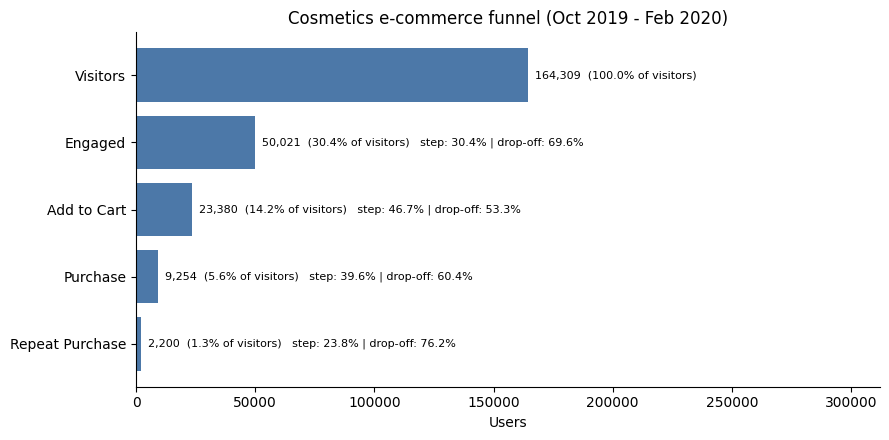

In [7]:
fig = plot_funnel(funnel, "Cosmetics e-commerce funnel (Oct 2019 - Feb 2020)")
fig.savefig(OUTPUTS / "funnel.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
worst = funnel.iloc[1:].sort_values("step_dropoff", ascending=False).iloc[0]
last = funnel.iloc[-1]
print(f"Largest step drop-off: '{worst['stage']}' - {worst['step_dropoff']:.1%} of users from the previous stage are lost.")
print(f"End-to-end: {last['overall_conversion']:.2%} of visitors become repeat purchasers.")

Largest step drop-off: 'Repeat Purchase' - 76.2% of users from the previous stage are lost.
End-to-end: 1.34% of visitors become repeat purchasers.


## Sensitivity: is the result driven by my definition of 'Engaged'?

In [9]:
rows = []
for k in [2, 3, 5, 10]:
    f = compute_funnel(users, orders, min_views=k)
    rows.append({"engaged_min_views": k, "engaged_users": f.loc[1, "users"],
                 "visitor->engaged": f.loc[1, "step_conversion"], "engaged->cart": f.loc[2, "step_conversion"],
                 "overall_purchase_rate": f.loc[3, "overall_conversion"]})
pd.DataFrame(rows)

,engaged_min_views,engaged_users,visitor->engaged,engaged->cart,overall_purchase_rate
0,2,75390,0.4588,0.3551,0.0601
1,3,50021,0.3044,0.4674,0.0563
2,5,30387,0.1849,0.6107,0.0496
3,10,15961,0.0971,0.7736,0.0386


## Funnel by acquisition cohort (month of first visit)

In [10]:
fc = funnel_by_cohort(users, orders)
(fc * 100).round(2)   # % of that cohort's visitors reaching each stage

stage,Visitors,Engaged,Add to Cart,Purchase,Repeat Purchase
2019-10,100.0000,34.4400,18.6900,8.5700,2.9600
2019-11,100.0000,34.1200,16.7300,6.6200,1.5500
2019-12,100.0000,29.4600,12.7000,4.8100,0.8500
2020-01,100.0000,27.9500,11.7700,4.1400,0.5900
2020-02,100.0000,24.9300,9.8400,3.1000,0.2500
